# Notebook 1 — Dataset y preprocesamiento

## Equipo
- Alumno 1 : CHIAPPE, Maximiliano Francisco - C-7542/6
- Alumno 2 : LENARDUZZI, Juan Sebastián - L-3398/7

## Dataset: Pins Face Recognition

Elegimos **[Pins Face Recognition](https://www.kaggle.com/datasets/hereisburak/pins-face-recognition)** (Kaggle): 105 identidades (celebridades) y 17534 imágenes, entre 86 y 237 por persona.

**Por qué este dataset:**
- Tiene muchas imágenes por persona, que es lo que necesita una CNN entrenada desde cero. En LFW, en cambio, la mayoría de las personas tiene una sola foto.
- Hay mucha variabilidad dentro de cada persona: pose, iluminación, expresión, edad, maquillaje y anteojos (lo mostramos en el EDA).
- Con 105 identidades alcanza para separar personas que el modelo nunca ve al entrenar, que es el caso real de la app: registrar gente nueva y reconocerla.

**Limitaciones:**
- Son solo celebridades, mayormente de Hollywood, jóvenes y de piel clara: sesgo demográfico (ver la sección de ética).
- Las imágenes vienen recortadas muy justas alrededor de la cara y muchas son de baja resolución.
- Muchas fotos son de alfombra roja o de películas (maquillaje, buena iluminación), distintas de una foto común tomada con el celular.

Lo descargamos con `kagglehub`, que lo guarda en la caché local, fuera del repositorio.

## Reproducibilidad

- **Semilla:** fijamos `SEED = 42` en `random` y `numpy`, así las muestras al azar y los splits salen siempre iguales.
- **Dataset:** descargamos siempre la versión 1 de Kaggle y comprobamos que tenga 17534 imágenes.
- **Modelos:** `det_10g.onnx` (detector) y `w600k_r50.onnx` (reconocimiento) vienen en el paquete `buffalo_l` de InsightFace y van en la carpeta `models/`. Verificamos con su hash SHA256 que sean exactamente los mismos archivos.
- **Librerías:** las notebooks se ejecutaron con Python 3.13 y GPU (CUDA 12.6); las versiones exactas están en `requirements-notebooks.txt`. La app usa `requirements.txt` (Python 3.12, Docker). Las dos comparten las mismas funciones de `src/lib/face_pipeline.py`, así que procesan las caras igual.


In [1]:
import random
import hashlib
import numpy as np
import kagglehub
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Dataset: versión fija
path = kagglehub.dataset_download("hereisburak/pins-face-recognition/versions/1")
DATA_DIR = Path(path) / "105_classes_pins_dataset"
assert len(list(DATA_DIR.glob("*/*.jpg"))) == 17534, "El dataset no es el esperado"

# Modelo del detector: tiene que ser exactamente este archivo
hash_det = hashlib.sha256(Path("models/det_10g.onnx").read_bytes()).hexdigest()
assert hash_det == "5838f7fe053675b1c7a08b633df49e7af5495cee0493c7dcf6697200b85b5b91", "det_10g.onnx distinto"

# Modelo de reconocimiento
hash_rec = hashlib.sha256(Path("models/w600k_r50.onnx").read_bytes()).hexdigest()
assert hash_rec == "4c06341c33c2ca1f86781dab0e829f88ad5b64be9fba56e56bc9ebdefc619e43", "w600k_r50.onnx distinto"

print("OK: dataset y modelo verificados")


c:\Users\maximiliano.chiappe\Desktop\Computer vision\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK: dataset y modelo verificados


## EDA — Imágenes por identidad

Contamos cuántas imágenes tiene cada persona para ver si el dataset está balanceado. Si algunas clases tienen muchas más imágenes que otras, el modelo puede sesgarse hacia ellas.


Identidades: 105  |  Imágenes: 17534
Media: 167.0  Mediana: 169  Mín: 86  Máx: 237
Menos imágenes:
  Lionel Messi 86
  Mark Zuckerberg 95
  Cristiano Ronaldo 98
Más imágenes:
  Katherine Langford 226
  Robert Downey Jr 233
  Leonardo DiCaprio 237


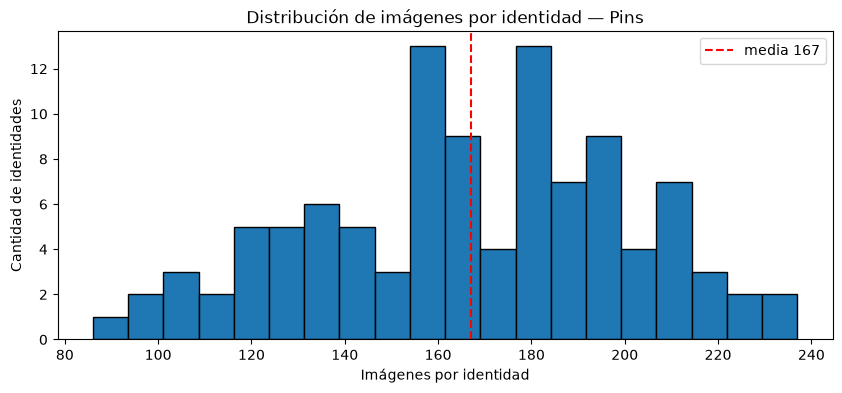

In [2]:
import matplotlib.pyplot as plt

# Una carpeta por persona: "pins_Nombre Apellido" -> "Nombre Apellido"
conteo = {}
for d in sorted(DATA_DIR.iterdir()):
    if d.is_dir():
        nombre = d.name.replace("pins_", "")
        conteo[nombre] = len(list(d.glob("*.jpg")))

cantidades = np.array(list(conteo.values()))

print(f"Identidades: {len(conteo)}  |  Imágenes: {cantidades.sum()}")
print(f"Media: {cantidades.mean():.1f}  Mediana: {np.median(cantidades):.0f}  "
      f"Mín: {cantidades.min()}  Máx: {cantidades.max()}")

orden = sorted(conteo, key=conteo.get)

print("Menos imágenes:")
for nombre in orden[:3]:
    print(" ", nombre, conteo[nombre])

print("Más imágenes:")
for nombre in orden[-3:]:
    print(" ", nombre, conteo[nombre])

plt.figure(figsize=(10, 4))
plt.hist(cantidades, bins=20, edgecolor="black")
plt.axvline(cantidades.mean(), color="red", linestyle="--", label=f"media {cantidades.mean():.0f}")
plt.xlabel("Imágenes por identidad")
plt.ylabel("Cantidad de identidades")
plt.title("Distribución de imágenes por identidad — Pins")
plt.legend()
plt.show()


El dataset tiene 105 identidades y 17534 imágenes. Todas las identidades tienen entre 86 y 237 imágenes (media 167, mediana 169): la que menos tiene es Lionel Messi (86) y la que más, Leonardo DiCaprio (237). El desbalance es moderado: la clase más grande tiene ~2.8 veces más imágenes que la más chica, así que no hace falta filtrar identidades por cantidad mínima. Igual lo tenemos en cuenta al entrenar, con class weights en la notebook 2.


## EDA — Resoluciones, formato y archivos corruptos

Revisamos el tamaño de cada imagen, si está en color o en escala de grises, y si hay archivos que no se pueden abrir. El modelo trabaja con caras de 112×112, así que nos interesa saber cuántas imágenes son más chicas que eso.


Leídas: 17534  |  Corruptas: 0
Extensiones: Counter({'.jpg': 17534})
Modos de color: Counter({'RGB': 17534})
Ancho  -> mín 80  mediana 175  máx 564
Alto   -> mín 82  mediana 185  máx 802
Más chicas que 112 px de lado: 2626


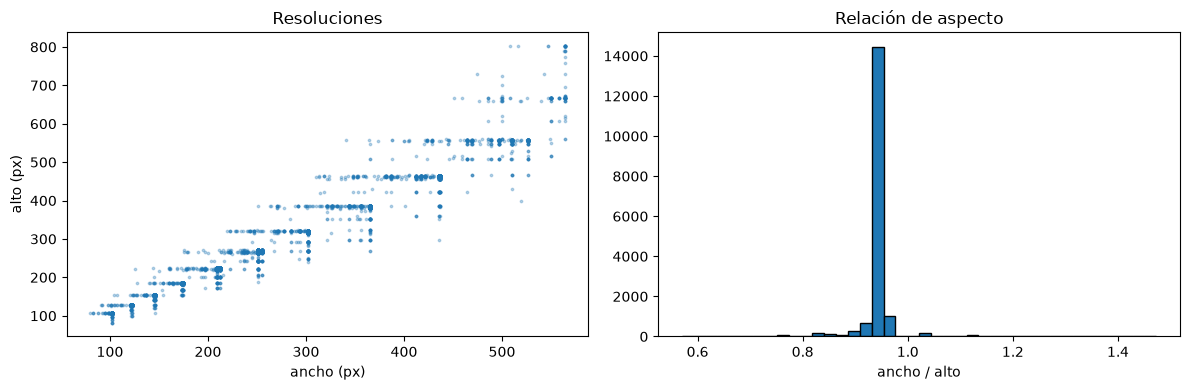

In [3]:
from collections import Counter
from PIL import Image

anchos = []
altos = []
modos = []
extensiones = []
corruptas = []

for d in sorted(DATA_DIR.iterdir()):
    for f in d.iterdir():
        extensiones.append(f.suffix.lower())
        try:
            with Image.open(f) as im:
                anchos.append(im.width)
                altos.append(im.height)
                modos.append(im.mode)
        except Exception:
            corruptas.append(f)

anchos = np.array(anchos)
altos = np.array(altos)

print(f"Leídas: {len(anchos)}  |  Corruptas: {len(corruptas)}")
print("Extensiones:", Counter(extensiones))
print("Modos de color:", Counter(modos))
print(f"Ancho  -> mín {anchos.min()}  mediana {np.median(anchos):.0f}  máx {anchos.max()}")
print(f"Alto   -> mín {altos.min()}  mediana {np.median(altos):.0f}  máx {altos.max()}")
print(f"Más chicas que 112 px de lado: {(np.minimum(anchos, altos) < 112).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(anchos, altos, s=3, alpha=0.3)
axes[0].set_xlabel("ancho (px)")
axes[0].set_ylabel("alto (px)")
axes[0].set_title("Resoluciones")
axes[1].hist(anchos / altos, bins=40, edgecolor="black")
axes[1].set_xlabel("ancho / alto")
axes[1].set_title("Relación de aspecto")
plt.tight_layout()
plt.show()


Ninguna imagen está corrupta, todas son RGB y todos los archivos son `.jpg` (no hay otras extensiones en las carpetas del dataset). Las imágenes son chicas (mediana 175×185 px) y casi todas tienen relación de aspecto ~0.94, lo que indica que Pins ya viene recortado alrededor del rostro: no son fotos completas. 2626 imágenes (15%) tienen un lado menor a 112 px; al llevarlas a 112×112 se agrandan y no ganan detalle real. No las descartamos acá: el filtro por tamaño mínimo lo aplicamos sobre la caja del rostro, en la etapa de limpieza.


## EDA — Muestra visual

Mostramos 8 imágenes al azar de 6 identidades para ver cómo son: variaciones de pose, iluminación, expresión y oclusiones (anteojos, pelo, manos), y si aparecen casos difíciles.


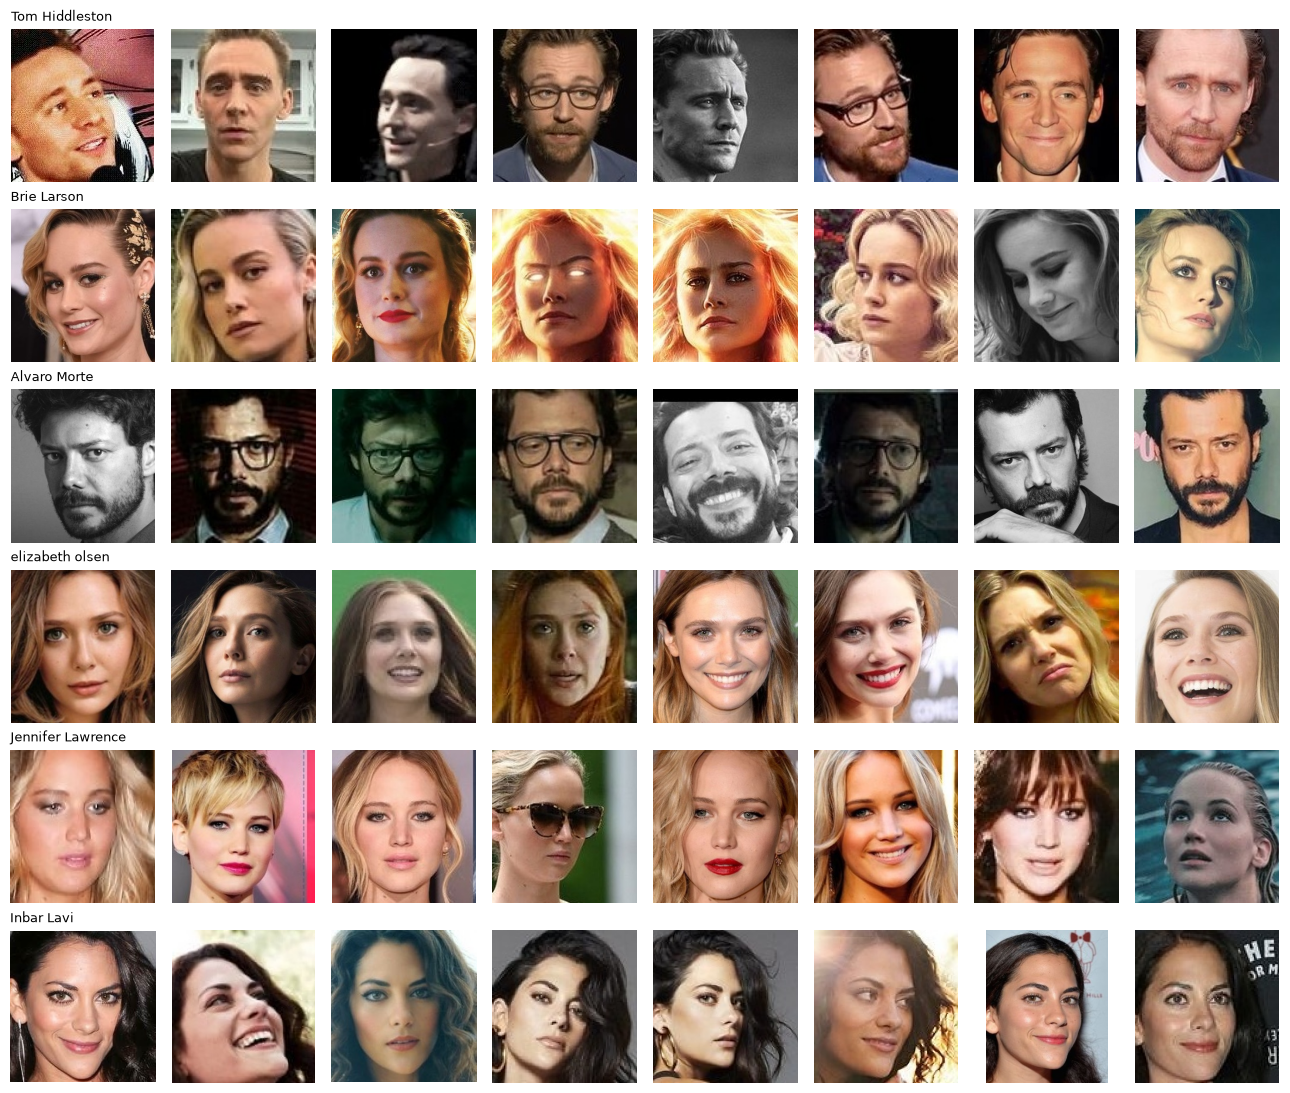

In [4]:
random.seed(SEED)

personas = random.sample(sorted(conteo), 6)   # 6 identidades al azar
N = 8                                         # imágenes por identidad

fig, axes = plt.subplots(6, N, figsize=(13, 11))
for i, p in enumerate(personas):
    archivos = random.sample(sorted((DATA_DIR / f"pins_{p}").glob("*.jpg")), N)
    for j, f in enumerate(archivos):
        axes[i, j].imshow(Image.open(f))
        axes[i, j].axis("off")
    axes[i, 0].set_title(p, fontsize=9, loc="left")
plt.tight_layout()
plt.show()


Se observa mucha variabilidad dentro de cada identidad:
- **Blanco y negro** (aunque estén guardadas como RGB): Tom Hiddleston, Álvaro Morte.
- **Iluminación muy distinta:** escenas oscuras o con luz de color (Álvaro Morte en verde, Brie Larson en naranja).
- **Caracterizaciones de personajes:** maquillaje y pósters editados, como Brie Larson con los ojos brillantes.
- **Anteojos**, incluidos de sol (Jennifer Lawrence), y cambios de peinado y color de pelo.
- **Poses y expresiones** muy distintas.

Además, muchos recortes son muy ajustados y cortan parte de la frente o el mentón. Estos son los casos que más le van a costar al modelo, y los tenemos en cuenta en la limpieza.


## EDA — Iluminación

Medimos el brillo (promedio de los píxeles en escala de grises) y el contraste (desvío estándar) de cada imagen. Sirve para ver si hay fotos muy oscuras, muy claras o planas, que después podemos revisar en la limpieza.


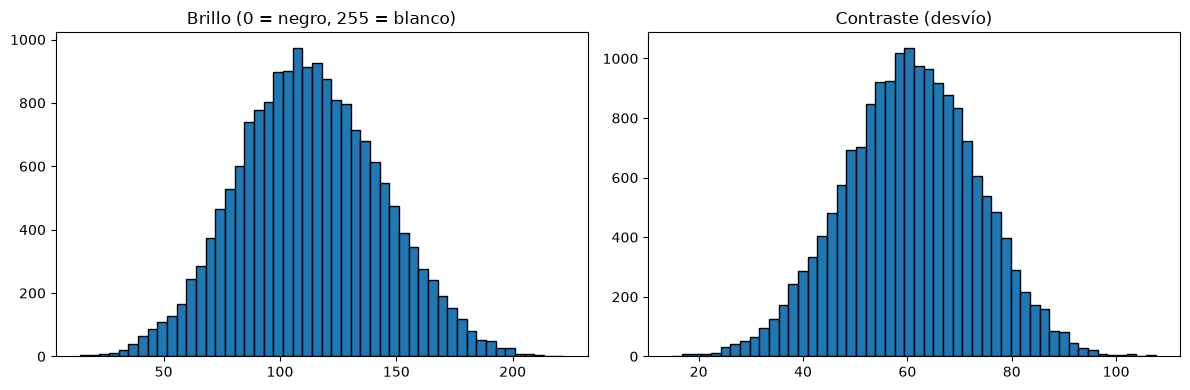

In [5]:
brillo = []
contraste = []

for f in DATA_DIR.glob("*/*.jpg"):
    img = np.array(Image.open(f).convert("L"))   # escala de grises
    brillo.append(img.mean())
    contraste.append(img.std())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(brillo, bins=50, edgecolor="black")
axes[0].set_title("Brillo (0 = negro, 255 = blanco)")
axes[1].hist(contraste, bins=50, edgecolor="black")
axes[1].set_title("Contraste (desvío)")
plt.tight_layout()
plt.show()


El brillo sigue una distribución tipo campana centrada en ~110 y el contraste en ~60, así que la mayoría de las imágenes tiene una exposición razonable. Hay pocas imágenes en los extremos: muy oscuras (brillo < 30), muy claras (brillo > 210) o con muy poco contraste (< 20). Esos son los umbrales que usamos después para marcarlas en la limpieza.


## Detección de rostros

Usamos el detector **SCRFD** (`det_10g.onnx`, de InsightFace) a través de `src/lib/face_pipeline.py`. Lo elegimos por tres motivos:
- Es el mismo que usa la app, así la notebook y la app procesan las caras exactamente igual.
- Además de la caja devuelve los 5 landmarks (ojos, nariz y comisuras), que necesitamos para alinear.
- Es robusto a perfiles parciales, cabezas inclinadas y oclusiones como anteojos o pelo.

Al probarlo sobre Pins, el detector no encontraba rostro en casi ninguna imagen (38 de 40 en una prueba), porque las imágenes vienen recortadas muy justas y la cara ocupa toda la foto. Lo resolvimos con `face_pipeline.detect_with_border`: si no encuentra rostro, vuelve a intentar con un borde negro alrededor de la imagen. La app usa la misma función, así que las fotos recortadas también funcionan ahí.


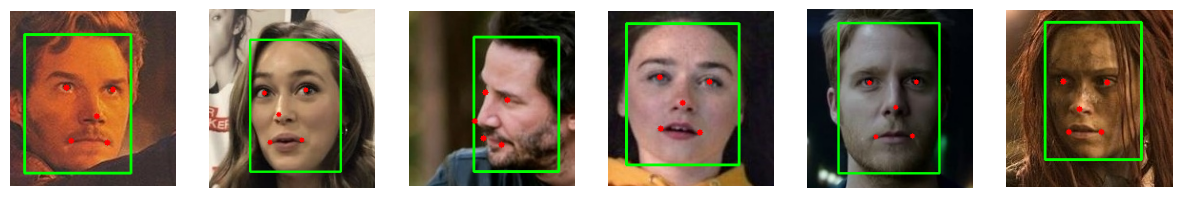

In [6]:
import sys
sys.path.append("src")

import cv2
from lib import face_pipeline

detector = face_pipeline.load_detector("models/det_10g.onnx")

# Probamos en algunas imágenes y dibujamos caja y landmarks
random.seed(SEED)
ejemplos = random.sample(sorted(DATA_DIR.glob("*/*.jpg")), 6)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, f in enumerate(ejemplos):
    img = cv2.imread(str(f))
    cajas, puntos = face_pipeline.detect_with_border(detector, img)
    for c in cajas:
        cv2.rectangle(img, (int(c[0]), int(c[1])), (int(c[2]), int(c[3])), (0, 255, 0), 2)
    for p in puntos:
        for x, y in p:
            cv2.circle(img, (int(x), int(y)), 3, (0, 0, 255), -1)
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].axis("off")
plt.show()


El detector encuentra el rostro y los 5 landmarks en los 6 ejemplos, incluso con la cara de perfil (3.ª imagen), la cabeza inclinada (4.ª), pelo tapando parte de la cara (2.ª) y maquillaje de personaje (6.ª). En la cabeza inclinada los landmarks siguen la inclinación, que es lo que después corregimos con la alineación.


## Detección sobre todo el dataset

Corremos el detector sobre las 17534 imágenes y guardamos las cajas y landmarks de cada una. Con esto después aplicamos las reglas de limpieza (sin rostro, más de un rostro, rostro chico). Guardamos el resultado en un archivo para no tener que repetir la detección, que tarda unos 25-30 minutos en CPU.


In [7]:
import pickle
from tqdm import tqdm

ARCHIVO = Path("data/detecciones.pkl")

if ARCHIVO.exists():
    resultados = pickle.load(open(ARCHIVO, "rb"))
else:
    resultados = []
    for f in tqdm(sorted(DATA_DIR.glob("*/*.jpg"))):
        cajas, puntos = face_pipeline.detect_with_border(detector, cv2.imread(str(f)))
        resultados.append({
            "ruta": str(f),
            "persona": f.parent.name.replace("pins_", ""),
            "cajas": cajas,
            "puntos": puntos,
        })
    pickle.dump(resultados, open(ARCHIVO, "wb"))

print("Imágenes procesadas:", len(resultados))

Imágenes procesadas: 17534


La detección sobre las 17534 imágenes tardó ~31 minutos en CPU, y encontró al menos un rostro en todas. El resultado quedó guardado en `data/detecciones.pkl`.


## EDA — Tamaño del rostro

Medimos el lado menor de la caja del rostro principal en cada imagen. Nos interesa compararlo con 112 px (el tamaño de entrada del modelo) y con 40 px (el mínimo que usamos en la limpieza).

Si una imagen tiene varias caras, tomamos la más grande (`cara_principal`), que es la persona etiquetada: Pins recorta centrado en ella.


Lado del rostro -> mín 45  mediana 119  máx 553
Rostros con lado menor a 112 px: 7974


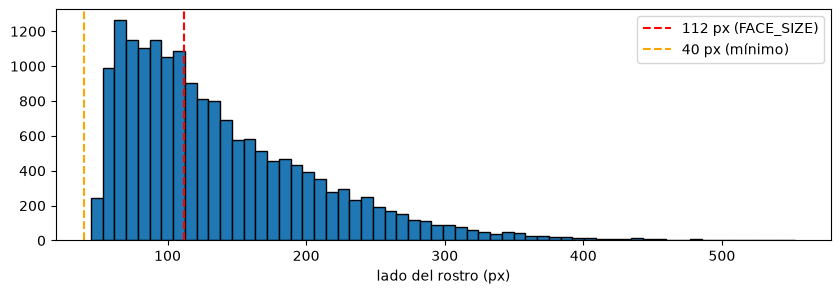

In [8]:
def cara_principal(r):
    # Si hay varias caras, devolvemos la más grande (caja y landmarks)
    areas = []
    for c in r["cajas"]:
        areas.append((c[2] - c[0]) * (c[3] - c[1]))
    i = int(np.argmax(areas))
    return r["cajas"][i], r["puntos"][i]

lados = []
for r in resultados:
    caja, puntos = cara_principal(r)
    lados.append(min(caja[2] - caja[0], caja[3] - caja[1]))
lados = np.array(lados)

print(f"Lado del rostro -> mín {lados.min():.0f}  mediana {np.median(lados):.0f}  máx {lados.max():.0f}")
print("Rostros con lado menor a 112 px:", (lados < 112).sum())

plt.figure(figsize=(10, 3))
plt.hist(lados, bins=60, edgecolor="black")
plt.axvline(112, color="red", linestyle="--", label="112 px (FACE_SIZE)")
plt.axvline(40, color="orange", linestyle="--", label="40 px (mínimo)")
plt.xlabel("lado del rostro (px)")
plt.legend()
plt.show()


El lado del rostro va de 45 a 553 px (mediana 119). Ninguno queda por debajo del mínimo de 40 px, pero el 45% (7974 rostros) mide menos de 112 px, así que al alinearlos a 112×112 se agrandan y tienen menos detalle real. Es una limitación del dataset: buena parte de las caras son de baja resolución, lo que puede afectar sobre todo a la CNN entrenada desde cero.


## Control de calidad — Reglas por detección

Revisamos tres casos con lo que devolvió el detector:
1. **Sin rostro:** el detector no encontró ninguna cara. Se descarta.
2. **Más de un rostro:** revisamos si la cara principal (la más grande) es la persona etiquetada, para no confundir de quién es la etiqueta.
3. **Rostro chico:** la cara principal tiene un lado menor a 40 px, con muy poco detalle para reconocer a la persona. Se descarta.

Contamos cuántas imágenes cae en cada caso y mostramos ejemplos de las que tienen más de un rostro.


Sin rostro:       0
Más de un rostro: 91
Rostro chico:     0


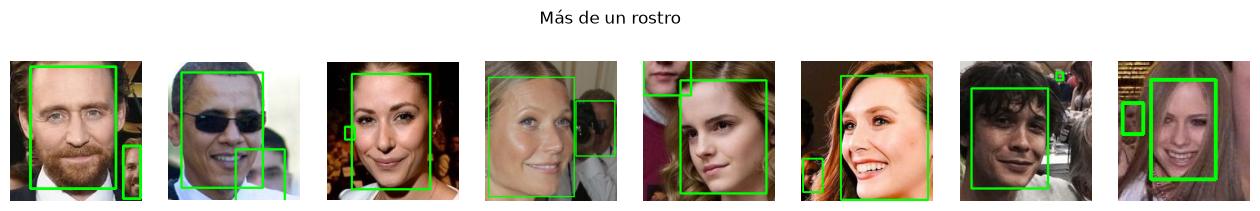

In [9]:
sin_rostro = []
varios_rostros = []
rostro_chico = []

for r in resultados:
    n = len(r["cajas"])
    if n == 0:
        sin_rostro.append(r)
    else:
        if n > 1:
            varios_rostros.append(r)
        caja, puntos = cara_principal(r)
        if min(caja[2] - caja[0], caja[3] - caja[1]) < 40:
            rostro_chico.append(r)

print("Sin rostro:      ", len(sin_rostro))
print("Más de un rostro:", len(varios_rostros))
print("Rostro chico:    ", len(rostro_chico))

def mostrar(lista, titulo, n=8):
    random.seed(SEED)
    lista = random.sample(lista, min(n, len(lista)))
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.5))
    for ax in axes:
        ax.axis("off")
    for i, r in enumerate(lista):
        img = cv2.imread(r["ruta"])
        for c in r["cajas"]:
            cv2.rectangle(img, (int(c[0]), int(c[1])), (int(c[2]), int(c[3])), (0, 255, 0), 2)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.suptitle(titulo)
    plt.show()

mostrar(varios_rostros, "Más de un rostro")


Ninguna imagen quedó sin rostro y ninguna tiene un rostro principal menor a 40 px, así que esas dos reglas no descartan nada. Hay 91 imágenes con más de un rostro, pero en los ejemplos la cara principal siempre es la más grande y está centrada (Pins recorta alrededor de la persona etiquetada). Las caras extra son personas de fondo cortadas en el borde o detecciones chicas que parecen falsos positivos. Por eso no descartamos estas imágenes: nos quedamos con la cara más grande de cada una.


## Control de calidad — Nitidez y exposición

**Borrosas:** usamos la varianza del Laplaciano. El Laplaciano resalta los bordes; en una imagen nítida hay muchos bordes marcados y la varianza es alta, en una borrosa es baja. Llevamos todas las imágenes a 112×112 antes de medir, para que el valor sea comparable entre imágenes de distinto tamaño. Umbral: varianza < 50.

**Exposición extrema:** marcamos las imágenes muy oscuras (brillo < 30), muy claras (brillo > 210) o con muy poco contraste (< 20), usando los extremos de los histogramas del EDA.

Los umbrales los elegimos mirando la distribución y los validamos con ejemplos de las imágenes marcadas, para decidir si descartarlas o no.


Borrosas:         29
Mala exposición:  42


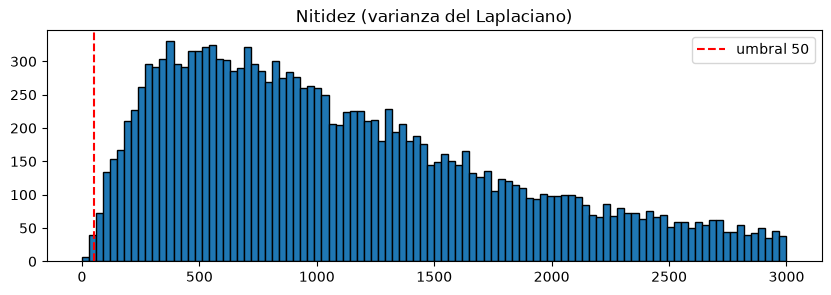

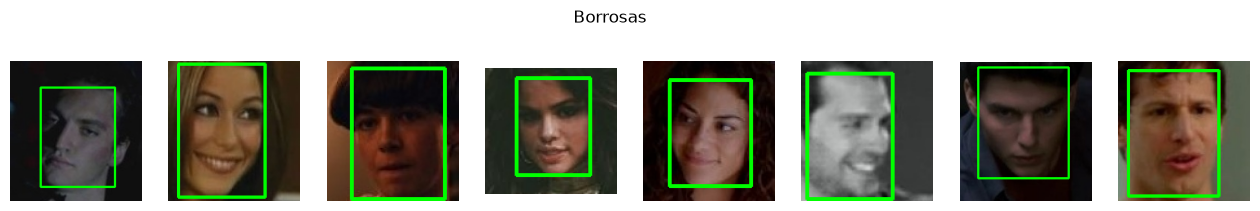

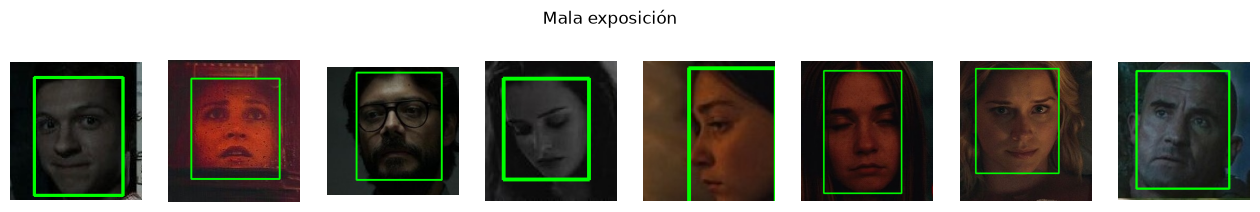

In [10]:
UMBRAL_BORROSA = 50
BRILLO_MIN, BRILLO_MAX = 30, 210
CONTRASTE_MIN = 20

nitidez = []
borrosas = []
mala_exposicion = []

for r in resultados:
    gris = cv2.imread(r["ruta"], cv2.IMREAD_GRAYSCALE)
    gris = cv2.resize(gris, (112, 112))

    varianza = cv2.Laplacian(gris, cv2.CV_64F).var()
    nitidez.append(varianza)
    if varianza < UMBRAL_BORROSA:
        borrosas.append(r)

    brillo = gris.mean()
    contraste = gris.std()
    if brillo < BRILLO_MIN or brillo > BRILLO_MAX or contraste < CONTRASTE_MIN:
        mala_exposicion.append(r)

print("Borrosas:        ", len(borrosas))
print("Mala exposición: ", len(mala_exposicion))

plt.figure(figsize=(10, 3))
plt.hist(nitidez, bins=100, range=(0, 3000), edgecolor="black")
plt.axvline(UMBRAL_BORROSA, color="red", linestyle="--", label=f"umbral {UMBRAL_BORROSA}")
plt.title("Nitidez (varianza del Laplaciano)")
plt.legend()
plt.show()

mostrar(borrosas, "Borrosas")
mostrar(mala_exposicion, "Mala exposición")

**Borrosas (29 imágenes):** el umbral de 50 corta solo la cola izquierda de la distribución (la mayoría del dataset está entre 200 y 3000). En los ejemplos todas son de muy mala calidad: pixeladas, desenfocadas o capturas de video agrandadas. Las descartamos.

**Mala exposición (42 imágenes):** los ejemplos son escenas oscuras o con poco contraste, pero en casi todas el rostro se reconoce bien. Son condiciones reales que también pueden aparecer en la app, así que no las descartamos: preferimos que el modelo aprenda a manejarlas, y para eso incluimos variaciones de brillo y contraste en el data augmentation.

## Alineación

Alineamos cada rostro con los 5 landmarks: una transformación de similitud (rotar, escalar y trasladar, sin deformar) lleva los ojos, la nariz y la boca a las posiciones fijas de la plantilla de ArcFace, y recorta a 112×112. Así todas las caras quedan en la misma posición, como espera el modelo. Usamos `face_pipeline.align`, la misma función que usa la app.

En las imágenes con más de un rostro usamos el más grande, como decidimos en la limpieza.


c:\Users\maximiliano.chiappe\Desktop\Computer vision\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


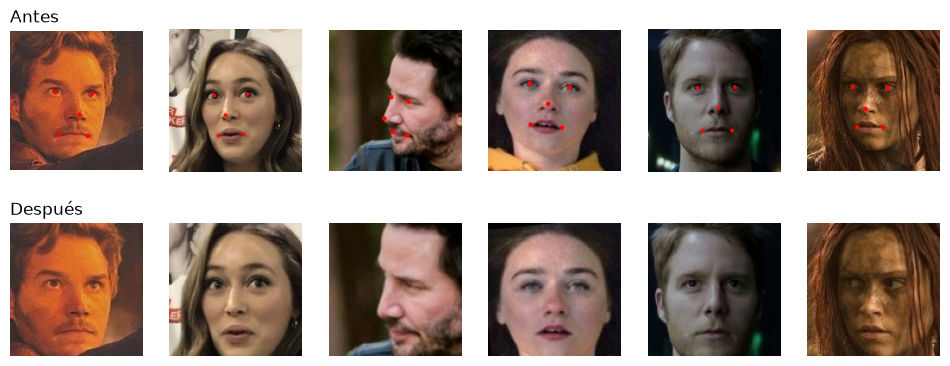

In [11]:
random.seed(SEED)
ejemplos = random.sample(resultados, 6)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i, r in enumerate(ejemplos):
    img = cv2.imread(r["ruta"])
    caja, puntos = cara_principal(r)
    alineada = face_pipeline.align(img, puntos, 112)

    for x, y in puntos:
        cv2.circle(img, (int(x), int(y)), 3, (0, 0, 255), -1)

    axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0, i].axis("off")
    axes[1, i].imshow(cv2.cvtColor(alineada, cv2.COLOR_BGR2RGB))
    axes[1, i].axis("off")

axes[0, 0].set_title("Antes", loc="left")
axes[1, 0].set_title("Después", loc="left")
plt.show()

La alineación endereza las cabezas inclinadas (4.ª imagen), normaliza la escala (5.ª) y deja ojos, nariz y boca siempre en la misma posición. Su límite son los perfiles (3.ª imagen): una transformación 2D no puede girar la cabeza, así que esas caras quedan alineadas solo parcialmente. Son casos difíciles para el reconocimiento.


## Embeddings

Para el análisis de duplicados y el clustering necesitamos representar cada cara como un vector. Usamos ArcFace (`w600k_r50.onnx`, de InsightFace), que da un vector de 512 números normalizado a largo 1: caras de la misma persona quedan cerca y de personas distintas, lejos.

Calculamos los embeddings sobre las imágenes que pasaron la limpieza (sacando las 29 borrosas). Tarda unos 20 minutos en CPU, así que guardamos el resultado en `data/embeddings.npy`.

In [12]:
import onnxruntime

# Sacamos las borrosas
rutas_borrosas = []
for r in borrosas:
    rutas_borrosas.append(r["ruta"])

curadas = []
for r in resultados:
    if r["ruta"] not in rutas_borrosas:
        curadas.append(r)
print("Imágenes curadas:", len(curadas))

modelo = onnxruntime.InferenceSession("models/w600k_r50.onnx")
entrada = modelo.get_inputs()[0].name

ARCHIVO_EMB = Path("data/embeddings.npy")

if ARCHIVO_EMB.exists():
    embeddings = np.load(ARCHIVO_EMB)
else:
    embeddings = []
    for r in tqdm(curadas):
        caja, puntos = cara_principal(r)
        cara = face_pipeline.align(cv2.imread(r["ruta"]), puntos, 112)
        x = face_pipeline.preprocess(cara)
        emb = modelo.run(None, {entrada: x})[0]
        embeddings.append(face_pipeline.l2_normalize(emb))
    embeddings = np.array(embeddings)
    np.save(ARCHIVO_EMB, embeddings)

print("Embeddings:", embeddings.shape)

Imágenes curadas: 17505
Embeddings: (17505, 512)


Se calcularon 17505 embeddings (las 17534 imágenes menos las 29 borrosas) en ~27 minutos. Quedan guardados en `data/embeddings.npy`.

## Control de calidad — Duplicados y casi-duplicados

Dos imágenes de la misma foto (o casi iguales: recortadas, comprimidas o con otro tamaño) tienen embeddings casi idénticos. Buscamos los pares con similitud coseno mayor a 0.95. Como los embeddings tienen largo 1, la similitud coseno es simplemente el producto punto.

Si una foto queda en train y su copia en test, el modelo "hace trampa": la reconoce porque ya la vio, no porque reconozca a la persona (fuga de datos). Por eso de cada par nos quedamos con una sola imagen.


Pares duplicados: 662
Imágenes a descartar: 587


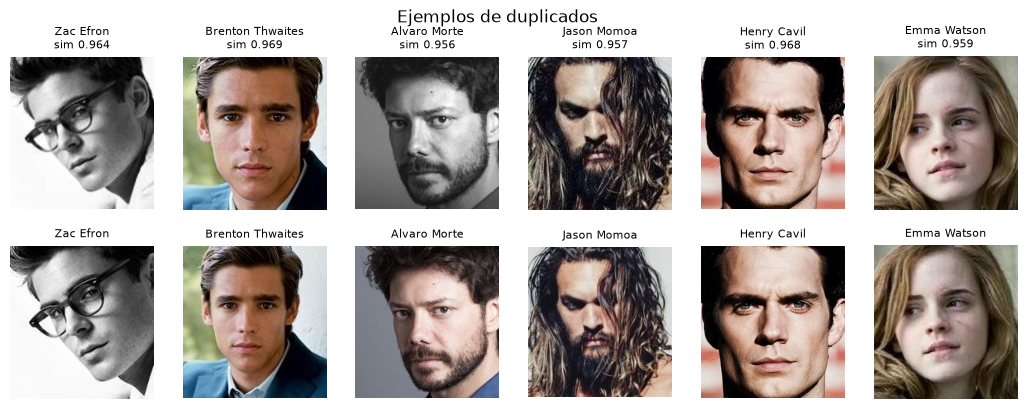

Pares de personas distintas: 1


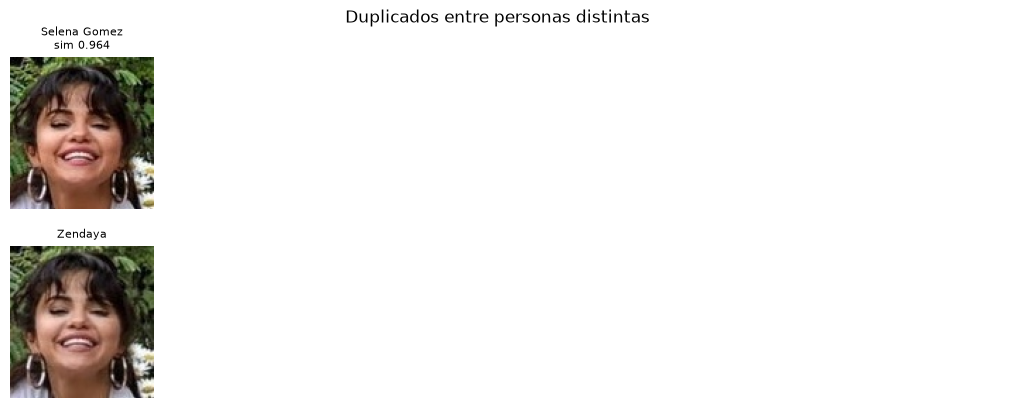

In [13]:
pares = []
for i in range(len(embeddings)):
    # Similitud de la foto i con todas las que vienen después
    sims = embeddings[i + 1:] @ embeddings[i]
    for j in np.where(sims > 0.95)[0]:
        pares.append((i, i + 1 + j, sims[j]))

# De cada par sacamos la segunda
duplicadas = set()
for a, b, s in pares:
    duplicadas.add(b)

print("Pares duplicados:", len(pares))
print("Imágenes a descartar:", len(duplicadas))

def mostrar_pares(lista, titulo):
    fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
    for ax in axes.flat:
        ax.axis("off")
    for k, (a, b, s) in enumerate(lista[:6]):
        axes[0, k].imshow(Image.open(curadas[a]["ruta"]))
        axes[0, k].set_title(f"{curadas[a]['persona']}\nsim {s:.3f}", fontsize=8)
        axes[1, k].imshow(Image.open(curadas[b]["ruta"]))
        axes[1, k].set_title(curadas[b]["persona"], fontsize=8)
    plt.suptitle(titulo)
    plt.show()

random.seed(SEED)
mostrar_pares(random.sample(pares, 6), "Ejemplos de duplicados")

distinta_persona = []
for a, b, s in pares:
    if curadas[a]["persona"] != curadas[b]["persona"]:
        distinta_persona.append((a, b, s))
print("Pares de personas distintas:", len(distinta_persona))
mostrar_pares(distinta_persona, "Duplicados entre personas distintas")

Encontramos 662 pares de casi-duplicados, que implican descartar 587 imágenes. En los ejemplos son la misma foto con distinto recorte, compresión o color (por ejemplo, Álvaro Morte en blanco y negro y en color). Hay un solo par entre personas distintas: la misma foto aparece en la carpeta de Selena Gomez y en la de Zendaya, así que en una de las dos está mal etiquetada. Al quedarnos con la primera imagen de cada par se conserva la de Selena Gomez y se descarta la copia de Zendaya.

## Resumen de la limpieza

Juntamos todas las reglas y armamos el dataset final. Las reglas de sin rostro y rostro chico no encontraron ninguna imagen, así que en la práctica descartamos las borrosas y los duplicados. Las de más de un rostro y las de mala exposición se quedan, por lo que vimos en sus ejemplos.


In [14]:
indices_finales = []
finales = []
for i in range(len(curadas)):
    if i not in duplicadas:
        indices_finales.append(i)
        finales.append(curadas[i])

embeddings_finales = embeddings[indices_finales]

personas_finales = set()
for r in finales:
    personas_finales.add(r["persona"])

print("Imágenes originales:       ", len(resultados))
print("  - sin rostro:            ", len(sin_rostro))
print("  - rostro chico:          ", len(rostro_chico))
print("  - borrosas:              ", len(borrosas))
print("  - duplicados:            ", len(duplicadas))
print("Imágenes finales:          ", len(finales))
print("Identidades:               ", len(personas_finales))


Imágenes originales:        17534
  - sin rostro:             0
  - rostro chico:           0
  - borrosas:               29
  - duplicados:             587
Imágenes finales:           16918
Identidades:                105


De 17534 imágenes quedan 16918 (se descartó el 3.5%), y se mantienen las 105 identidades. La mayor parte de lo descartado son duplicados (587); las borrosas son pocas (29). Ninguna imagen quedó sin rostro, gracias a que el detector reintenta con un borde negro cuando no encuentra la cara, y ninguna tiene un rostro menor a 40 px.

## Clustering exploratorio

Usamos los embeddings de ArcFace para ver si las imágenes de cada persona quedan agrupadas. K-Means arma los grupos sin mirar las etiquetas, así que si sus grupos coinciden con las personas, las etiquetas del dataset son confiables; si no coinciden, puede haber fotos mal etiquetadas.

Aplicamos K-Means con 105 clusters (uno por identidad) y comparamos los clusters con las etiquetas reales:
- **ARI** (Adjusted Rand Index): 1 = los clusters coinciden perfecto con las etiquetas, 0 = al azar.
- **NMI** (Normalized Mutual Information): misma idea, de 0 a 1.
- **Silhouette**: mide qué tan cerca está cada imagen de su propia clase comparado con la clase más cercana (de -1 a 1; más alto es mejor).


In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

etiquetas = []
for r in finales:
    etiquetas.append(r["persona"])

kmeans = KMeans(n_clusters=105, random_state=SEED, n_init=10)
kmeans.fit(embeddings_finales)

print("ARI:       ", adjusted_rand_score(etiquetas, kmeans.labels_))
print("NMI:       ", normalized_mutual_info_score(etiquetas, kmeans.labels_))
print("Silhouette:", silhouette_score(embeddings_finales, etiquetas, metric="cosine",
                                      sample_size=5000, random_state=SEED))

ARI:        0.9745027900486856
NMI:        0.9941715264223796
Silhouette: 0.48390576243400574


ARI = 0.97 y NMI = 0.99: los clusters de K-Means, armados sin ver las etiquetas, coinciden casi perfecto con las identidades reales. El silhouette (0.48) es positivo: cada imagen está en promedio más cerca de su propia identidad que de la más cercana, aunque hay bastante variación dentro de cada persona (pose, edad, maquillaje). Esto indica que el dataset está bien etiquetado en general y que los embeddings de ArcFace separan bien a las personas.

### ¿Qué identidades se mezclan?

Buscamos dos cosas:
- **Clusters mezclados:** la segunda persona más común del cluster tiene más del 20% de las imágenes que la primera.
- **Identidades repartidas:** menos del 95% de las imágenes de una persona cayó en su cluster principal.


In [16]:
etiquetas_np = np.array(etiquetas)

print("Clusters con dos identidades mezcladas:")
for k in range(105):
    en_cluster = Counter(etiquetas_np[kmeans.labels_ == k])
    comunes = en_cluster.most_common(2)
    if len(comunes) == 2:
        (p1, n1), (p2, n2) = comunes
        if n2 > 0.2 * n1:
            print(f"  Cluster {k}: {p1} ({n1}) y {p2} ({n2})")

print("Identidades repartidas (menos del 95% en un mismo cluster):")
for p in sorted(set(etiquetas)):
    sus_clusters = kmeans.labels_[etiquetas_np == p]
    n_principal = Counter(sus_clusters).most_common(1)[0][1]
    porcentaje = n_principal / len(sus_clusters)
    if porcentaje < 0.95:
        print(f"  {p}: {porcentaje:.0%} en su cluster principal")

Clusters con dos identidades mezcladas:
  Cluster 3: Lili Reinhart (144) y Maria Pedraza (117)
  Cluster 63: Robert De Niro (149) y jeff bezos (91)
Identidades repartidas (menos del 95% en un mismo cluster):
  Selena Gomez: 66% en su cluster principal
  Sophie Turner: 65% en su cluster principal


K-Means juntó dos pares de identidades en un mismo cluster:
- Lili Reinhart (144 imágenes) con Maria Pedraza (117).
- Robert De Niro (149) con Jeff Bezos (91).

Como tiene que armar exactamente 105 clusters, para compensar partió a otras dos identidades: Selena Gomez (66% de sus imágenes en el cluster principal) y Sophie Turner (65%).

Fuera de estos casos, las identidades quedan casi enteras en su propio cluster. Que dos personas compartan cluster no significa que estén mal etiquetadas: K-Means agrupa por cercanía, y esos pares están más cerca entre sí que el resto. El t-SNE de abajo muestra, para 15 identidades al azar, cómo se separan en general.


## Proyección t-SNE

Proyectamos los embeddings de 512 dimensiones a 2D con t-SNE para visualizarlos, coloreando por identidad. Usamos 15 identidades al azar, porque con 105 colores el gráfico no se puede leer.


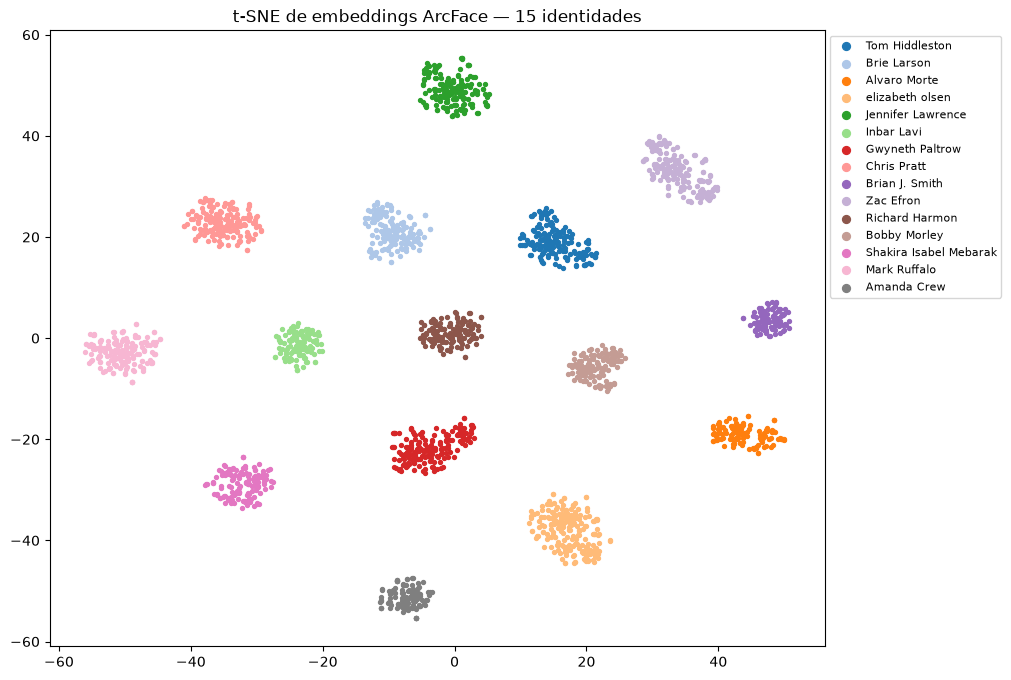

In [17]:
from sklearn.manifold import TSNE

random.seed(SEED)
elegidas = random.sample(sorted(set(etiquetas)), 15)

idx = []
for i, p in enumerate(etiquetas):
    if p in elegidas:
        idx.append(i)

tsne = TSNE(n_components=2, metric="cosine", random_state=SEED)
puntos_2d = tsne.fit_transform(embeddings_finales[idx])
etiquetas_idx = etiquetas_np[idx]

plt.figure(figsize=(10, 8))
for k, p in enumerate(elegidas):
    m = etiquetas_idx == p
    plt.scatter(puntos_2d[m, 0], puntos_2d[m, 1], s=8, label=p, color=plt.cm.tab20(k))
plt.legend(fontsize=8, markerscale=2, bbox_to_anchor=(1, 1))
plt.title("t-SNE de embeddings ArcFace — 15 identidades")
plt.show()


Cada identidad forma un grupo compacto y separado de los demás, sin mezclas entre personas, lo que coincide con el ARI de 0.97. Algunas identidades muestran sub-grupos dentro de su propio grupo (por ejemplo Zac Efron, Elizabeth Olsen, Álvaro Morte o Gwyneth Paltrow), posiblemente por condiciones de captura distintas: fotos de distintas épocas, caracterizaciones de personajes o fotos en blanco y negro. Es una hipótesis: no lo verificamos foto por foto.

## Outliers y posibles errores de etiquetado

Para cada identidad calculamos su "centro" (el promedio de sus embeddings) y medimos qué tan parecida es cada imagen a ese centro. Las imágenes con menor similitud son las que están lejos de su propia clase: pueden ser fotos mal etiquetadas o casos muy difíciles (perfil, maquillaje, mala calidad). Marcamos como outliers las que tienen similitud menor a 0.3 con su centro.

Imágenes con similitud a su centro < 0.3: 11


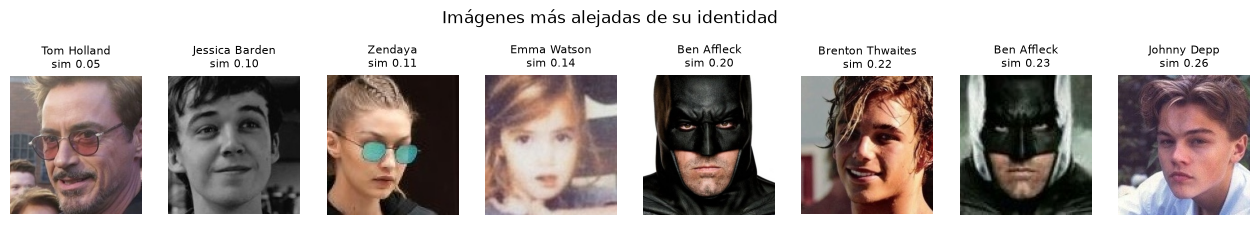

In [18]:
centroides = {}
for p in set(etiquetas):
    c = embeddings_finales[etiquetas_np == p].mean(axis=0)
    centroides[p] = c / np.linalg.norm(c)

sim_centroide = []
for i, p in enumerate(etiquetas):
    sim_centroide.append(embeddings_finales[i] @ centroides[p])
sim_centroide = np.array(sim_centroide)

print("Imágenes con similitud a su centro < 0.3:", (sim_centroide < 0.3).sum())

peores = np.argsort(sim_centroide)[:8]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.8))
for k, i in enumerate(peores):
    axes[k].imshow(Image.open(finales[i]["ruta"]))
    axes[k].set_title(f"{etiquetas[i]}\nsim {sim_centroide[i]:.2f}", fontsize=8)
    axes[k].axis("off")
plt.suptitle("Imágenes más alejadas de su identidad")
plt.show()

Las imágenes más alejadas de su identidad muestran dos tipos de casos: oclusiones o variaciones extremas (máscara de Batman, una foto de la infancia, anteojos de sol) y posibles errores de etiquetado. Como son muy pocas (11 imágenes con similitud a su centro menor a 0.3) y en ambos casos agregan más ruido que información para entrenar, las descartamos.

Descartamos los 11 outliers y actualizamos las imágenes, los embeddings y las etiquetas.


In [19]:
quedan = sim_centroide >= 0.3

nuevas_finales = []
for i in range(len(finales)):
    if quedan[i]:
        nuevas_finales.append(finales[i])
finales = nuevas_finales

embeddings_finales = embeddings_finales[quedan]

etiquetas = []
for r in finales:
    etiquetas.append(r["persona"])
etiquetas_np = np.array(etiquetas)

print("Imágenes finales:", len(finales))

Imágenes finales: 16907


Después de sacar los 11 outliers quedan **16907 imágenes** de 105 identidades. Este es el dataset final que usamos para los splits.


## Data augmentation

Definimos transformaciones que simulan variaciones reales de una foto de rostro, para que el modelo vea más variedad durante el entrenamiento. Se aplican sobre la cara ya alineada (112×112) y **solo en el conjunto de entrenamiento**, nunca en validación ni test.

**Acá solo definimos y visualizamos el pipeline: no generamos ni guardamos imágenes aumentadas.** Se aplica en la notebook 2, en el momento de entrenar (cada época ve versiones distintas), y solo sobre el split de train. Así no hay riesgo de que una versión aumentada de una foto quede en train y la original en test.

| Transformación | Por qué la incluimos |
|---|---|
| Flip horizontal | Una cara espejada sigue siendo la misma persona |
| Rotación ±10°, traslación ±5%, escala ±5% | Pequeños errores de alineación |
| Brillo y contraste | Distintas iluminaciones (vimos escenas oscuras en el EDA) |
| Tono y saturación (leve) | Distintas cámaras y balances de color |
| Desenfoque y ruido | Fotos de baja calidad o capturas de video |
| Coarse dropout | Oclusiones: anteojos, manos, pelo |
| Compresión JPEG | Imágenes comprimidas de internet |

**Excluimos** el flip vertical y las rotaciones grandes (una cara dada vuelta no ocurre en la realidad) y las deformaciones geométricas fuertes, porque cambian las proporciones de la cara, que es justamente lo que define la identidad.

**Desbalance:** no usamos augmentation para compensar el desbalance de clases, porque es moderado (de 86 a 237 imágenes por persona). En la notebook 2 lo manejamos con *class weights* en la loss, que es más simple y no genera imágenes artificiales de más para algunas personas.


c:\Users\maximiliano.chiappe\Desktop\Computer vision\.venv\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


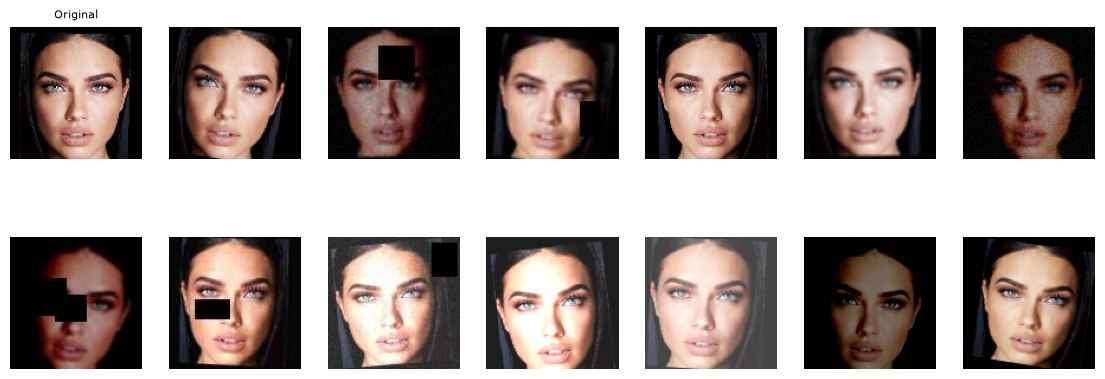

In [20]:
import albumentations as A

augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=20, val_shift_limit=0, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.15, 0.3), hole_width_range=(0.15, 0.3), p=0.3),
    A.ImageCompression(quality_range=(40, 90), p=0.3),
], seed=SEED)

# Misma cara, 13 versiones aumentadas
r = finales[0]
caja, puntos = cara_principal(r)
cara = face_pipeline.align(cv2.imread(r["ruta"]), puntos, 112)
cara = cv2.cvtColor(cara, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(2, 7, figsize=(14, 5))
axes = axes.flat
axes[0].imshow(cara)
axes[0].set_title("Original", fontsize=8)
for k in range(1, 14):
    axes[k].imshow(augmentation(image=cara)["image"])
for ax in axes:
    ax.axis("off")
plt.show()

Cada versión aumentada combina distintas transformaciones: flips, pequeñas rotaciones (se ve el borde negro en las esquinas), cambios de brillo y contraste, desenfoque, ruido y oclusiones simuladas (los rectángulos negros del coarse dropout). En todas la persona sigue siendo reconocible, que es lo que buscamos: más variedad sin cambiar la identidad.


## Splits

Separamos las 105 identidades en tres grupos (al azar, con semilla fija):
- **75 identidades conocidas:** sus imágenes se reparten 80% train, 10% val y 10% test. Es el escenario **closed-set**: mismas personas, fotos distintas. Con train entrenamos, con val elegimos la mejor época y los hiperparámetros, y con test medimos el accuracy final del clasificador.
- **15 identidades nuevas para validación** (`val_nuevas`) y **15 para test** (`test_nuevas`): personas que el modelo nunca ve al entrenar. Es el escenario **open-set**, el caso real de la app. Con `val_nuevas` calibramos el umbral y con `test_nuevas` reportamos el resultado final.

Guardamos el split en `splits/splits.csv` con rutas relativas al dataset, para que la notebook 2 lo reutilice en cualquier máquina.


In [21]:
import csv

personas = sorted(set(etiquetas))
random.seed(SEED)
random.shuffle(personas)
conocidas = personas[:75]
nuevas_val = personas[75:90]
nuevas_test = personas[90:]

split = [""] * len(finales)

for p in conocidas:
    # Índices de las fotos de esta persona
    idx = []
    for i in range(len(etiquetas)):
        if etiquetas[i] == p:
            idx.append(i)
    random.shuffle(idx)

    n_train = int(len(idx) * 0.8)
    n_val = int(len(idx) * 0.1)
    for i in idx[:n_train]:
        split[i] = "train"
    for i in idx[n_train:n_train + n_val]:
        split[i] = "val"
    for i in idx[n_train + n_val:]:
        split[i] = "test"

for i in range(len(etiquetas)):
    if etiquetas[i] in nuevas_val:
        split[i] = "val_nuevas"
    if etiquetas[i] in nuevas_test:
        split[i] = "test_nuevas"

Path("splits").mkdir(exist_ok=True)
with open("splits/splits.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["ruta", "persona", "split"])
    for r, s in zip(finales, split):
        ruta = Path(r["ruta"]).relative_to(DATA_DIR).as_posix()
        w.writerow([ruta, r["persona"], s])

split = np.array(split)
for s in ["train", "val", "test", "val_nuevas", "test_nuevas"]:
    n_imagenes = (split == s).sum()
    n_personas = len(set(etiquetas_np[split == s]))
    print(f"{s:12} imágenes: {n_imagenes:5}   identidades: {n_personas}")

train        imágenes:  9625   identidades: 75
val          imágenes:  1172   identidades: 75
test         imágenes:  1270   identidades: 75
val_nuevas   imágenes:  2418   identidades: 15
test_nuevas  imágenes:  2422   identidades: 15


| Split | Imágenes | Identidades | Uso |
|---|---|---|---|
| train | 9625 | 75 | Entrenamiento |
| val | 1172 | 75 | Early stopping y elección de hiperparámetros |
| test | 1270 | 75 | Accuracy closed-set del clasificador |
| val_nuevas | 2418 | 15 | Calibración del umbral (open-set) |
| test_nuevas | 2422 | 15 | Resultado final open-set: verificación, identificación y clustering |
| **Total** | **16907** | **105** | |

Las 75 identidades conocidas aparecen en train, val y test con imágenes distintas. Las 30 identidades nuevas nunca aparecen en train. El split quedó guardado en `splits/splits.csv`.

## Verificación de fuga de datos

Chequeamos que ninguna imagen de val, test, val_nuevas o test_nuevas sea casi igual a una de train (similitud mayor a 0.95). Si la hubiera, el modelo podría "reconocer" la foto en vez de la persona y los resultados serían engañosamente buenos.


In [22]:
emb_train = embeddings_finales[split == "train"]
emb_resto = embeddings_finales[split != "train"]

max_sim = (emb_resto @ emb_train.T).max()
print("Máxima similitud entre train y el resto:", round(float(max_sim), 4))

if max_sim <= 0.95:
    print("Sin fuga de datos")
else:
    print("HAY FUGA DE DATOS")

Máxima similitud entre train y el resto: 0.95
Sin fuga de datos


La máxima similitud entre una imagen de train y cualquiera de los otros splits es 0.95 (redondeado: queda apenas por debajo del umbral), así que no hay duplicados ni casi-duplicados repartidos entre splits. El valor queda justo debajo del umbral porque la limpieza de duplicados eliminó todos los pares por encima de 0.95. Como limitación, puede haber fotos muy parecidas (por ejemplo, de una misma sesión) con similitud apenas menor que siguen en splits distintos.

## Ética, privacidad y licencias

**Licencia del dataset.** Pins Face Recognition se publicó en Kaggle a partir de imágenes de Pinterest, con licencia **CC0: Public Domain** (según la página del dataset). Esa licencia la declara quien armó el dataset: las fotos son de celebridades y los derechos de cada imagen siguen siendo de sus autores (fotógrafos, productoras). Por eso lo usamos solo con fines académicos y sin redistribuir las imágenes: el dataset no se sube al repositorio (`data/*` está en el `.gitignore`) y se descarga desde Kaggle.

**Modelos.** Según el README de InsightFace, sus modelos preentrenados (`det_10g.onnx`, `w600k_r50.onnx`) están disponibles solo para uso no comercial / investigación, lo que es compatible con un trabajo práctico. Tampoco los subimos al repositorio (`*.onnx` está en el `.gitignore`).

**Sesgos.** El dataset tiene solo celebridades, mayormente actores y actrices de Hollywood, con predominio de personas jóvenes y de piel clara, fotografiadas en condiciones favorables (maquillaje, buena iluminación, alfombras rojas). Un modelo entrenado o evaluado con estos datos puede rendir peor con personas mayores, de otros tonos de piel o con fotos de baja calidad, y las métricas que reportamos pueden ser optimistas para un uso real.

**Privacidad.** Los rostros son datos biométricos: permiten identificar a una persona de forma única. En Argentina, la Ley 25.326 de Protección de Datos Personales exige consentimiento informado para tratar datos personales y da protección especial a los datos sensibles; según el uso, los datos biométricos pueden quedar alcanzados por esa protección. Para usar la app con personas reales (por ejemplo, registrar compañeros) hay que pedir su consentimiento explícito y no guardar sus fotos ni embeddings más allá de lo necesario.

**Riesgos del reconocimiento facial.** Puede usarse para vigilancia masiva o seguimiento de personas sin su conocimiento, y los errores (falsos positivos) pueden tener consecuencias graves si se usa para decisiones sobre personas. Por eso el umbral de decisión debe calibrarse con cuidado y un sistema así no debería usarse sin supervisión humana.


## Resumen

| Etapa | Resultado |
|---|---|
| Dataset | Pins Face Recognition: 105 identidades, 17534 imágenes |
| Detección | SCRFD (`detect_with_border`, igual que la app): rostro en el 100% de las imágenes |
| Limpieza | Se descartan 29 borrosas, 587 duplicados y 11 outliers → **16907 imágenes**. Sin fuga de datos entre splits |
| Alineación | 5 landmarks → plantilla ArcFace, 112×112 (`face_pipeline.align`, igual que la app) |
| Clustering | ARI 0.97 · NMI 0.99 · silhouette 0.48 |
| Augmentation | Definido acá, se aplica solo a train en la notebook 2 |
| Splits | 75 identidades conocidas (train 9625 / val 1172 / test 1270) + 15 nuevas para validación (2418) + 15 nuevas para test (2422) |

Archivos que genera esta notebook: `data/detecciones.pkl` y `data/embeddings.npy` (cachés, fuera del repo) y `splits/splits.csv` (en el repo).
